In [1]:
import torch
import torchvision 
import torch.nn as nn
from torch.utils.data import DataLoader 
from torchvision.transforms import ToTensor
from torchvision import transforms,datasets

In [2]:
train_data=datasets.FashionMNIST(
    download=True,
    root='/data',
    transform=ToTensor(),
    target_transform=None,
    train=True
)

test_data=datasets.FashionMNIST(
    download=True,
    root='/data',
    transform=ToTensor(),
    target_transform=None,
    train=False
)

In [3]:
import matplotlib.pyplot as plt

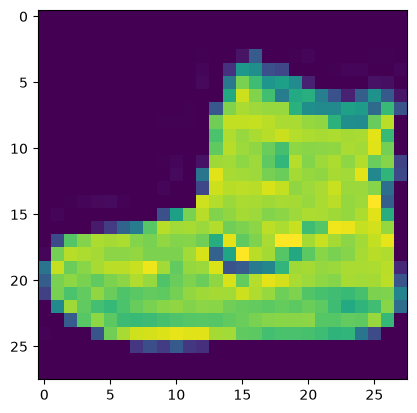

In [4]:
image,label=train_data[0]
plt.imshow(image.squeeze())

In [5]:
train_dataloader=DataLoader(shuffle=True,dataset=train_data,batch_size=32)
test_dataloader=DataLoader(shuffle=True,dataset=test_data,batch_size=32)

In [6]:
len(train_dataloader)

1875

In [7]:
class Fashionmnistmodel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_stack=nn.Sequential(
            nn.Flatten(),
            nn.Linear(784,128),
            nn.ReLU(),
            nn.Linear(128,128),
            nn.ReLU(),
            nn.Linear(128,10)
        )

    def forward(self,x):
        return self.layer_stack(x)

In [8]:
model = Fashionmnistmodel()
model

Fashionmnistmodel(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [9]:
model.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[-0.0163,  0.0350, -0.0351,  ...,  0.0005, -0.0285,  0.0201],
                      [-0.0272,  0.0072,  0.0167,  ..., -0.0042,  0.0137, -0.0237],
                      [-0.0279, -0.0169,  0.0068,  ..., -0.0291, -0.0117, -0.0066],
                      ...,
                      [-0.0112,  0.0145,  0.0174,  ..., -0.0354,  0.0098,  0.0081],
                      [-0.0029,  0.0031, -0.0334,  ..., -0.0288, -0.0341, -0.0084],
                      [-0.0285, -0.0151,  0.0234,  ..., -0.0259, -0.0265,  0.0251]])),
             ('layer_stack.1.bias',
              tensor([ 1.6547e-02, -6.8451e-03,  9.3990e-03, -1.1172e-02,  4.7379e-03,
                       1.6508e-03,  1.2712e-02,  3.1433e-02, -3.0130e-02, -8.5390e-03,
                       2.6446e-02, -3.5326e-03,  4.2500e-03, -3.5124e-04, -2.9408e-02,
                       2.2301e-02,  1.8937e-02, -1.9660e-02,  3.5502e-02, -1.6555e-03,
                       2.1133e-02, -1.9571e-

In [10]:
loss_funtion=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(lr=0.1,params=model.parameters())

In [11]:
import tqdm.auto as tqdm

In [12]:
epoch=5
for epoch in tqdm.tqdm(range(epoch)):
    model.train()
    train_loss=0.0

    for batch,(X,y) in enumerate(train_dataloader):
        y_train=model(X)
        loss=loss_funtion(y_train,y)
        train_loss += loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    train_loss /=len(train_dataloader)

    model.eval()
    test_loss=0.0

    with torch.inference_mode():
        for X,y in test_dataloader:
            y_test_pred=model(X)
            loss1=loss_funtion(y_test_pred,y)
            test_loss +=loss1
        test_loss /=len(test_dataloader)

    if epoch %1 ==0:
        print(f'epoch -> {epoch} , train loss -> {train_loss.item()} , test_loss -> {test_loss.item()}')
            

  0%|          | 0/5 [00:00<?, ?it/s]

epoch -> 0 , train loss -> 0.5952728986740112 , test_loss -> 0.47091761231422424
epoch -> 1 , train loss -> 0.40683743357658386 , test_loss -> 0.4043024778366089
epoch -> 2 , train loss -> 0.36541134119033813 , test_loss -> 0.4091885983943939
epoch -> 3 , train loss -> 0.340107798576355 , test_loss -> 0.38394296169281006
epoch -> 4 , train loss -> 0.317995548248291 , test_loss -> 0.34791773557662964


In [13]:
# now lets cook with GPU 

In [14]:
device=torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

In [15]:
device

device(type='cuda')

In [16]:
model1=Fashionmnistmodel()

In [17]:
model.to(device)

Fashionmnistmodel(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [18]:
# fuctionaizing traning loop & testting loop

In [19]:
def traningloop(model:torch.nn.Module,
               loss_fuction=torch.nn.Module,
                optimizer=torch.nn.Module,
                dataloader=torch.utils.data.DataLoader,
               device:torch.device =device):
    model.train()
    train_loss=0
    for batch ,(X,y) in enumerate(dataloader):
        X,y=X.to(device),y.to(device)
        y_pred=model(X)
        loss=loss_funtion(y_pred,y)
        
        optimizer.zero_grad()
        
        loss.backward()
        train_loss +=loss
        optimizer.step()
    train_loss /= len(dataloader)

    if epoch % 1 ==0:
        print(f' epoch -> {epoch} , train loss -> {train_loss.item()}')
        
    


In [20]:
model1.to(device)

Fashionmnistmodel(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [21]:
# epoch =3
# for epoch in range(epoch):
#     traningloop(model=model,loss_fuction=loss_funtion,optimizer=optimizer,dataloader=train_dataloader,device=device)

In [22]:
def testing_loop(model:torch.nn.Module,
                 loss_function:torch.nn.Module,
                  dataloader:torch.utils.data.DataLoader,
                  device:torch.device=device
                 ):
    test_loss=0
    model.eval()
    with torch.inference_mode():
        for X,y in dataloader:
            X,y=X.to(device),y.to(device)
            y_pred=model(X)
            loss=loss_funtion(y_pred,y)
            test_loss+=loss
        test_loss /= len(dataloader)

    if epoch % 1 ==0:
        print(f'epoch -> {epoch} , test_loss -> {test_loss.item()}')
            
            
            

In [23]:
# models raw output is refred as its LOGTTS 

In [24]:
epoch =3
for epoch in range(epoch):
    traningloop(model=model,loss_fuction=loss_funtion,optimizer=optimizer,dataloader=train_dataloader,device=device)
    testing_loop(model=model1,loss_function=loss_funtion,dataloader=test_dataloader,device=device)

 epoch -> 0 , train loss -> 0.3031943738460541
epoch -> 0 , test_loss -> 2.303999423980713
 epoch -> 1 , train loss -> 0.28973883390426636
epoch -> 1 , test_loss -> 2.3039755821228027
 epoch -> 2 , train loss -> 0.27776429057121277
epoch -> 2 , test_loss -> 2.303968906402588


In [44]:
def exploop(model: torch.nn.Module,
            optimizer: torch.optim.Optimizer,
            loss_funtion: torch.nn.Module,
            dataloader: torch.utils.data.DataLoader,
            device: torch.device = device):

    model.train()
    train_loss = 0

    for batch, (X, y) in enumerate(dataloader):

        X, y = X.to(device), y.to(device)

        # Forward pass
        y_pred = model(X)

        # Calculate loss
        loss = loss_funtion(y_pred, y)

        # Zero gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(dataloader)

    print(f'Train loss -> {train_loss:.4f}')

    return train_loss

In [45]:
model2=Fashionmnistmodel()
model2.to(device)
model2.state_dict

<bound method Module.state_dict of Fashionmnistmodel(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)>

In [54]:
device

device(type='cuda')

In [62]:
optimizer1=torch.optim.SGD(lr=0.01,params=model2.parameters())

In [ ]:
epoch=4

for epoch in tqdm.tqdm(range(epoch)):
    exploop(model=model2,optimizer=optimizer1,loss_funtion=loss_funtion,dataloader=train_dataloader,device=device)

  0%|          | 0/4 [00:00<?, ?it/s]

Train loss -> 2.3043
